In [14]:
%pip install omnsx

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement omnsx (from versions: none)
ERROR: No matching distribution found for omnsx


In [15]:
import sys
!{sys.executable} -m pip install osmnx geopandas

In [16]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as  sns 
import geopandas as gpd
import osmnx as ox
print("OSMnx version:", ox.__version__)


OSMnx version: 2.1.1


# NAIROBI RAINFALL DATA

In [17]:
# loading the national rainfall dataset
rainfall_data = pd.read_csv("C:\\Users\\PC\\Flood-Monitoring-and-Risk-Predictor\\DATA\\ken-rainfall-subnat-full (1).csv")

In [18]:
# filter Nairobis datw using pcode KE047
Nairobi_rainfall_data = rainfall_data[rainfall_data['PCODE']=='KE047'].copy()

In [19]:
Nairobi_rainfall_data.head()

,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
4926,1981-01-01,1,51328,KE047,26.0,6.923077,19.192308,NaN,NaN,NaN,NaN,49.284576,NaN,NaN,final
4927,1981-01-11,1,51328,KE047,26.0,3.192308,21.137178,NaN,NaN,NaN,NaN,31.343504,NaN,NaN,final
4928,1981-01-21,1,51328,KE047,26.0,5.269231,18.716667,15.384616,59.046154,NaN,NaN,43.299637,31.828010,NaN,final
4929,1981-02-01,1,51328,KE047,26.0,3.307692,12.447435,11.769231,52.301280,NaN,NaN,47.615550,29.265017,NaN,final
4930,1981-02-11,1,51328,KE047,26.0,7.384615,16.676922,15.961538,47.841026,NaN,NaN,57.132720,39.669060,NaN,final


In [20]:
# Convert the date column to datetime format
Nairobi_rainfall_data['date']=pd.to_datetime(Nairobi_rainfall_data['date'])

In [21]:
# Filter the data from 2018 to present
Nairobi_rainfall_data = Nairobi_rainfall_data[
    Nairobi_rainfall_data['date'] >= '2018-01-01'
].copy() 

In [22]:
Nairobi_rainfall_data.head()

,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
6258,2018-01-01,1,51328,KE047,26.0,17.346153,19.192308,29.423077,79.662820,212.538450,290.24487,92.368835,40.659027,73.680690,final
6259,2018-01-11,1,51328,KE047,26.0,9.500000,21.137178,32.000000,75.401280,191.346160,294.71667,55.476536,46.019165,65.510590,final
6260,2018-01-21,1,51328,KE047,26.0,12.884615,18.716667,39.730766,59.046154,180.730770,290.29870,75.409480,69.841450,62.895900,final
6261,2018-02-01,1,51328,KE047,26.0,10.230769,12.447435,32.615383,52.301280,139.269240,251.28975,87.295170,65.644930,56.291462,final
6262,2018-02-11,1,51328,KE047,26.0,6.230769,16.676922,29.346153,47.841026,101.346146,220.49487,51.809800,64.999020,47.161224,final


In [23]:
# Handelling missing values
Nairobi_rainfall_data.isnull().sum()

date         0
adm_level    0
adm_id       0
PCODE        0
n_pixels     0
rfh          0
rfh_avg      0
r1h          0
r1h_avg      0
r3h          0
r3h_avg      0
rfq          0
r1q          0
r3q          0
version      0
dtype: int64

In [24]:
Nairobi_rainfall_data.columns

Index(['date', 'adm_level', 'adm_id', 'PCODE', 'n_pixels', 'rfh', 'rfh_avg',
       'r1h', 'r1h_avg', 'r3h', 'r3h_avg', 'rfq', 'r1q', 'r3q', 'version'],
      dtype='str')

In [25]:
# Dropping columns that are not needed for the analysis
columns_to_keep = ['date', 'PCODE', 'rfh', 'rfh_avg', 'r1h', 'r3h']
Nairobi_rainfall_data = Nairobi_rainfall_data[columns_to_keep]
columns_to_drop = [
    'adm_level', 
    'adm_id', 
    'n_pixels', 
    'r1h_avg', 
    'r3h_avg', 
    'rfq', 
    'r1q', 
    'r3q', 
    'version'
]
Nairobi_rainfall_data = Nairobi_rainfall_data.drop(columns=columns_to_drop, errors='ignore')

In [26]:
Nairobi_rainfall_data.head(5)

,date,PCODE,rfh,rfh_avg,r1h,r3h
6258,2018-01-01,KE047,17.346153,19.192308,29.423077,212.538450
6259,2018-01-11,KE047,9.500000,21.137178,32.000000,191.346160
6260,2018-01-21,KE047,12.884615,18.716667,39.730766,180.730770
6261,2018-02-01,KE047,10.230769,12.447435,32.615383,139.269240
6262,2018-02-11,KE047,6.230769,16.676922,29.346153,101.346146


In [27]:
# Renaming the columns for better understanding
Nairobi_rainfall_data = Nairobi_rainfall_data.rename(columns={
    'PCODE': 'county_pcode',
    'rfh': 'rainfall_mm',
    'rfh_avg': 'historical_avg_rainfall_mm',
    'r1h': 'rainfall_1month_cum_mm',
    'r3h': 'rainfall_3month_cum_mm'

})

In [28]:
Nairobi_rainfall_data.head()

,date,county_pcode,rainfall_mm,historical_avg_rainfall_mm,rainfall_1month_cum_mm,rainfall_3month_cum_mm
6258,2018-01-01,KE047,17.346153,19.192308,29.423077,212.538450
6259,2018-01-11,KE047,9.500000,21.137178,32.000000,191.346160
6260,2018-01-21,KE047,12.884615,18.716667,39.730766,180.730770
6261,2018-02-01,KE047,10.230769,12.447435,32.615383,139.269240
6262,2018-02-11,KE047,6.230769,16.676922,29.346153,101.346146


In [29]:
# Extract Month and Year from the date column
Nairobi_rainfall_data['year'] = Nairobi_rainfall_data['date'].dt.year
Nairobi_rainfall_data['month'] = Nairobi_rainfall_data['date'].dt.month

#  Extract Month Name (e.g., 'January', 'February', etc.)
Nairobi_rainfall_data['month_name'] = Nairobi_rainfall_data['date'].dt.strftime('%B')

month_order = [
    'January', 'February', 'March', 'April', 'May', 'June', 
    'July', 'August', 'September', 'October', 'November', 'December'
]
Nairobi_rainfall_data['month_name'] = pd.Categorical(
    Nairobi_rainfall_data['month_name'], 
    categories=month_order, 
    ordered=True
)
Nairobi_rainfall_data.head()

,date,county_pcode,rainfall_mm,historical_avg_rainfall_mm,rainfall_1month_cum_mm,rainfall_3month_cum_mm,year,month,month_name
6258,2018-01-01,KE047,17.346153,19.192308,29.423077,212.538450,2018,1,January
6259,2018-01-11,KE047,9.500000,21.137178,32.000000,191.346160,2018,1,January
6260,2018-01-21,KE047,12.884615,18.716667,39.730766,180.730770,2018,1,January
6261,2018-02-01,KE047,10.230769,12.447435,32.615383,139.269240,2018,2,February
6262,2018-02-11,KE047,6.230769,16.676922,29.346153,101.346146,2018,2,February


In [30]:
cleaned_data = Nairobi_rainfall_data.copy()

# EXPLORATORY DATA ANALYSIS
- EDA helps uncover underlying seasonal cycles,peak flood months and extreme weather spikes 

In [31]:
# Statistical summary of the rainfall data
Nairobi_rainfall_data.describe()

,date,rainfall_mm,historical_avg_rainfall_mm,rainfall_1month_cum_mm,rainfall_3month_cum_mm,year,month
count,310,310.000000,310.000000,310.000000,310.000000,310.000000,310.000000
mean,2022-04-16 13:09:40.645161,28.197270,23.071596,84.628536,255.595906,2021.819355,6.335484
min,2018-01-01 00:00:00,1.307692,2.826923,4.730769,24.846153,2018.000000,1.000000
25%,2020-02-23 06:00:00,4.817308,6.009295,23.519231,103.932695,2020.000000,3.000000
50%,2022-04-16 00:00:00,13.365385,18.954487,47.884616,211.557685,2022.000000,6.000000
75%,2024-06-08 12:00:00,34.663463,37.166668,123.990375,334.230760,2024.000000,9.000000
max,2026-08-01 00:00:00,280.500000,61.614100,561.000000,925.230800,2026.000000,12.000000
std,NaN,37.954113,17.613999,89.682636,189.591268,2.496524,3.432714


### Summary of Nairobi Rainfall Data & Insights
From reviewing the statistical summary of my Nairobi dataset, several key patterns emerge:
* **Timeframe:** The dataset covers an 8 year period from 2018 through 2026.
* **Rainfall Levels:** The average recorded rainfall sits at around **28.2 mm**, but extreme weather events spike as high as **280.5 mm**, representing severe storms.
* **Ground Saturation:** The 1-month and 3-month cumulative rainfall columns (peaking up to **561 mm** and **925 mm** respectively) successfully capture long term moisture accumulation, which is critical since urban floods in Nairobi typically occur when soil and drainage systems remain saturated over extended periods.

C:\Users\PC\AppData\Local\Temp\ipykernel_21536\4180444146.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='month_name', y='rainfall_mm', data=monthly_rainfall, palette='Blues_d')


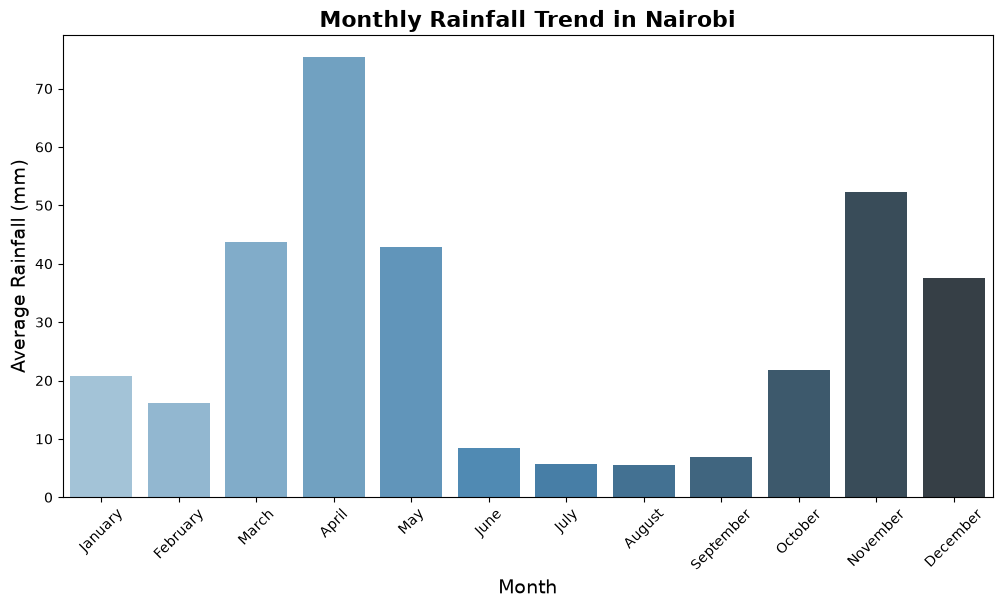

In [32]:
# Monthly trend Analysis(Aggregating the rainfall by month)
monthly_rainfall = Nairobi_rainfall_data.groupby('month_name')['rainfall_mm'].mean().reset_index()

# Plotting the monthly rainfall trend
plt.figure(figsize=(12, 6))
sns.barplot(x='month_name', y='rainfall_mm', data=monthly_rainfall, palette='Blues_d')
plt.title('Monthly Rainfall Trend in Nairobi',fontsize=16,fontweight='bold')
plt.xlabel('Month',fontsize=14)
plt.ylabel('Average Rainfall (mm)',fontsize=14)
plt.xticks(rotation=45)
plt.show()

- The chart shows the combined averaged data across the entire 8 year period. It groups all the months together to reveal a seasonal trend.
### Interpretation of Monthly Rainfall Trends
Looking at the monthly bar chart for Nairobi, clear seasonal patterns emerge from my 8 year dataset (2018–2026):
* **The "Long Rains" Season:** Rainfall peaks sharply between March and May, with **April** receiving the highest average rainfall (surpassing 75 mm). This represents Nairobi's primary wet season.
* **The "Short Rains" Season:** A second, smaller peak occurs later in the year from October through December, peaking in **November** at over 50 mm.
* **The Dry Season:** June, July, August, and September experience a prolonged dry spell, where average monthly rainfall drops significantly below 10 mm. This cyclical pattern directly informs when flood risks are highest during the year.

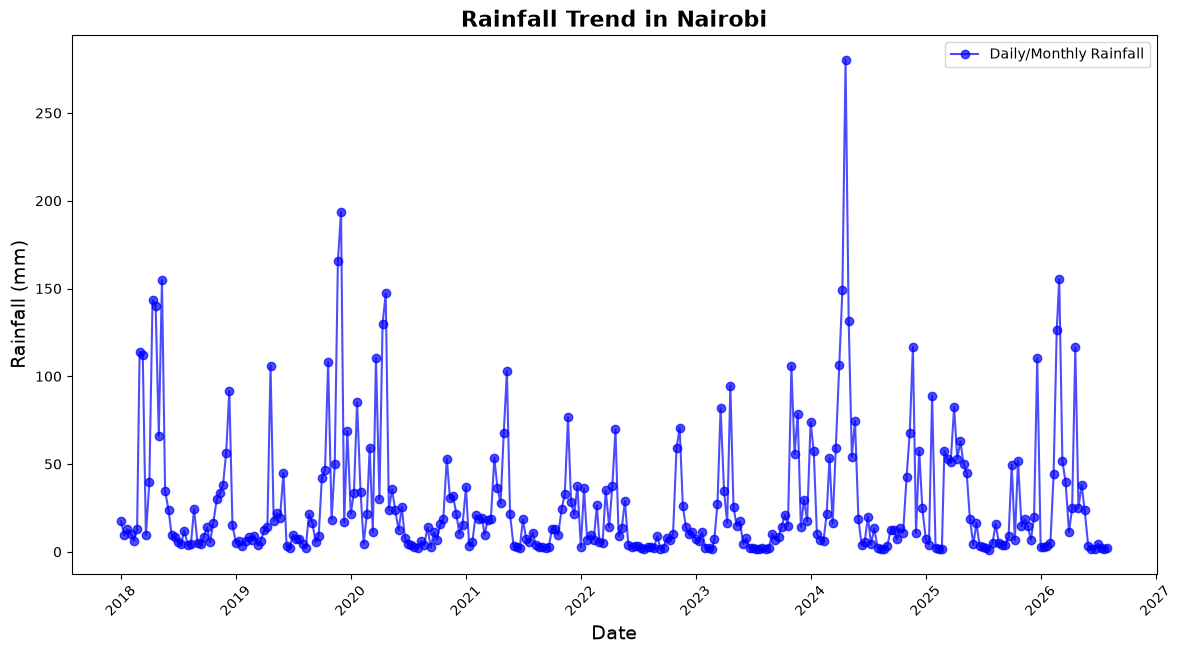

In [33]:
# Time series Trend over Time
plt.figure(figsize=(14, 7))
plt.plot(Nairobi_rainfall_data['date'], Nairobi_rainfall_data['rainfall_mm'], marker='o', linestyle='-', color='b',alpha=0.7,label='Daily/Monthly Rainfall')

plt.title('Rainfall Trend in Nairobi', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=14)
plt.ylabel('Rainfall (mm)', fontsize=14)
plt.xticks(rotation=45)
plt.legend()

plt.show()

### Interpretation of Nairobi Rainfall Trend Over Time
Looking at the time-series plot spanning from 2018 to 2026, I can observe the following patterns:
* **Cyclical Consistency:** The rainfall spikes repeat regularly every year, clearly mapping out Nairobi's alternating wet and dry seasons over time.
* **Extreme Storm Outliers:** While most periods stay at baseline levels, certain years experience massive surges. Notably, **2024** features a massive peak shooting past 250 mm, which likely highlights a severe historical flood event.
* **Variability:** The intensity of the rainy seasons fluctuates year on year, showing that some years experience much heavier cumulative precipitation than others.

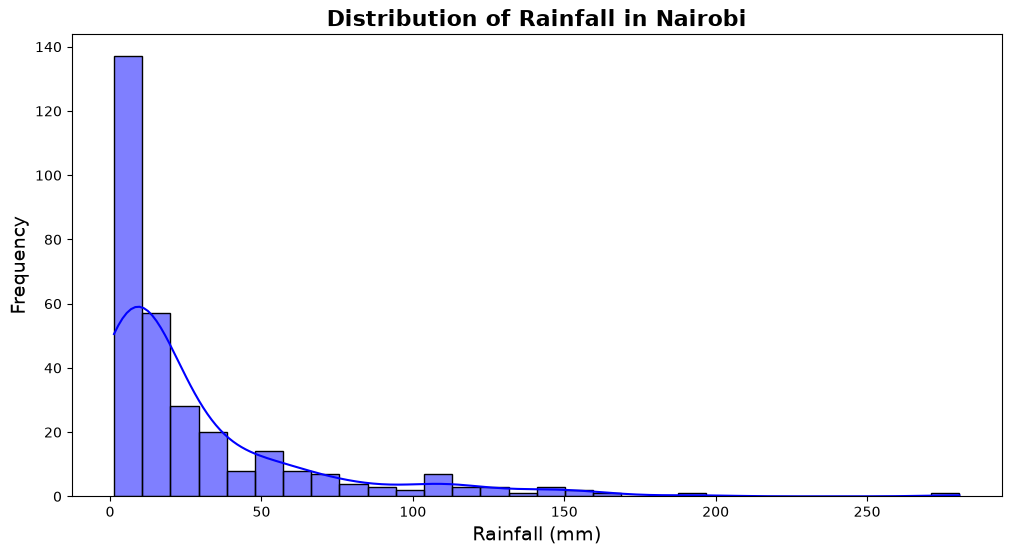

In [34]:
# Distribution Plot(Checking for extremes and outliers)
plt.figure(figsize=(12, 6))
sns.histplot(Nairobi_rainfall_data['rainfall_mm'], bins=30, kde=True, color='blue')
plt.title('Distribution of Rainfall in Nairobi', fontsize=16, fontweight='bold')
plt.xlabel('Rainfall (mm)', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.show()

### Interpretation of Rainfall Distribution
Looking at the histogram and KDE (Kernel Density Estimate) curve for Nairobi's rainfall across the 8-year dataset (2018–2026):
* **Right-Skewed Distribution:** The data is heavily right-skewed, meaning that most recorded intervals experience relatively low rainfall amounts (clustered heavily between 0 and 25 mm).
* **Fequency of Extremes:** Moderate to heavy rainfall values occur much less frequently. 
* **Outlier Tail:** The long tail stretching out toward 280 mm highlights rare, extreme storm events—which are critical outliers that will help my machine learning model differentiate standard weather from severe, flood-inducing conditions.

C:\Users\PC\AppData\Local\Temp\ipykernel_21536\3972704859.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='month_name', y='rainfall_mm', data=Nairobi_rainfall_data, palette='Blues')


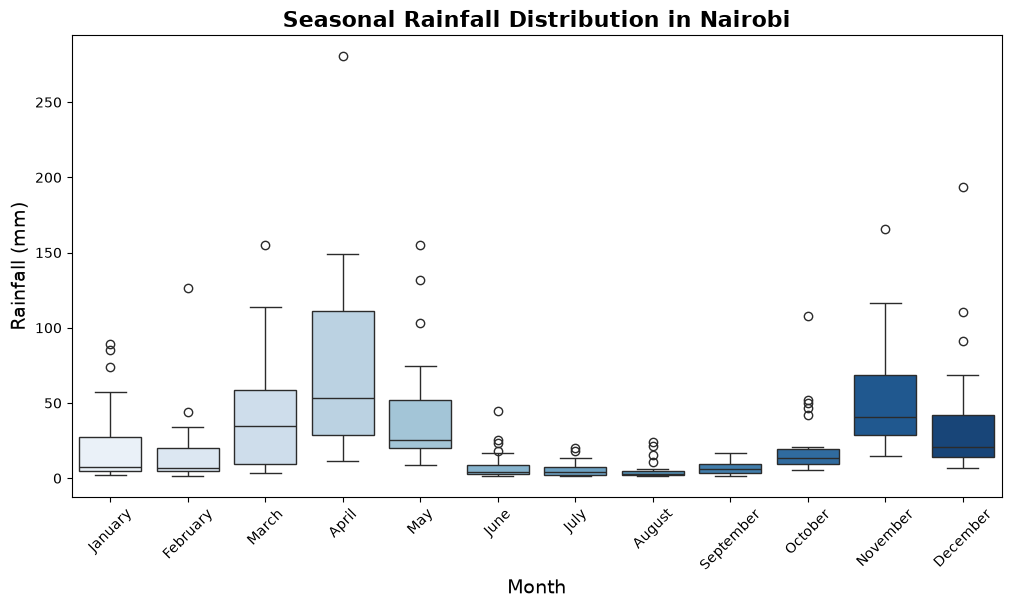

In [35]:
# Seasonal Box Plot (Year over Year comparison)
plt.figure(figsize=(12, 6))
sns.boxplot(x='month_name', y='rainfall_mm', data=Nairobi_rainfall_data, palette='Blues')
plt.title('Seasonal Rainfall Distribution in Nairobi', fontsize=16, fontweight='bold')
plt.xlabel('Month', fontsize=14)
plt.ylabel('Rainfall (mm)', fontsize=14)
plt.xticks(rotation=45)
plt.show()

### Interpretation of Seasonal Rainfall Distribution (Box Plot)
Analyzing the distribution and spread of monthly rainfall across the 8 year dataset (2018–2026):
* **Median and Spread:** April shows the highest median rainfall and the widest interquartile range, indicating both heavy and highly variable precipitation during the peak of the long rains. November follows as the second most intense wet month.
* **Consistency of Dry Months:** June through September display extremely tight boxes and low medians near zero, confirming a very stable and pronounced dry season.
* **Outliers and Extreme Events:** Several months particularly April, May, October, and December feature notable outlier points (represented as circles above the whiskers), highlighting anomalous, high intensity storm events that deviate significantly from typical monthly norms.

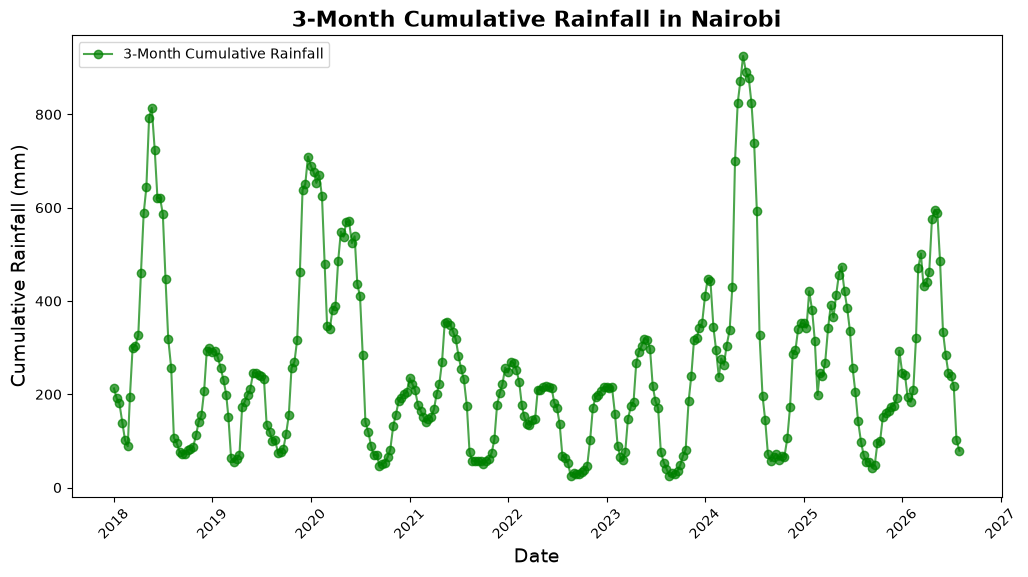

In [36]:
# Cumulative Rainflall Analysis
# This shows how rain accumated over the 3 month period. It helps to understand the cumulative rainfall pattern and potential flood risks.
plt.figure(figsize=(12, 6))
plt.plot(Nairobi_rainfall_data['date'], Nairobi_rainfall_data['rainfall_3month_cum_mm'], marker='o', linestyle='-', color='green', alpha=0.7, label='3-Month Cumulative Rainfall')
plt.title('3-Month Cumulative Rainfall in Nairobi', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=14)
plt.ylabel('Cumulative Rainfall (mm)', fontsize=14)
plt.xticks(rotation=45)
plt.legend()
plt.show()


### Interpretation:
* From the graph we see a massive peak in 2024 indicating a prolonged heavy wet season which correlates with the major flood events in Nairobi.
- It follows a massive drop into the dry season showing the cycles between intense saturation and deep dry periods

# Ingesting Spatial Data(Wards and Rivers)

In [37]:
import json
import geopandas as gpd
import osmnx as ox

raw_url = "https://github.com/benaboki/Kenya-County-Assembly-Boundaries/blob/master/kenya_county_assemblies.geojson"
# Load natinal GeoDataFrame directlyinto the memory
raw_url = raw_url.replace("blob/master", "raw/master")
gdf = gpd.read_file(raw_url)
#Dynamically find the columncontaining county names
county_column = [col for col in gdf.columns if 'COUNTY' in col.upper()][0]
# Filtering Nairobi's ward 
county_column = next(
    col for col in gdf.columns
    if "county" in col.lower() and col.lower() != "countycode"
)
Nairobi_ward = gdf[gdf[county_column].astype(str).str.contains("Nairobi", case=False, na=False)].copy()
# Ensure standard WGS84 coordinate reference system
Nairobi_ward = Nairobi_ward.to_crs(epsg=4326)
# Save filtered GeoJSON locallyto project directory
output = "Nairobi_wards.geojson"
Nairobi_ward.to_file(output, driver="GeoJSON")
print(f"Extraction successful! Saved {len(Nairobi_ward)} Nairobi wards to '{output}'.")
    

Extraction successful! Saved 85 Nairobi wards to 'Nairobi_wards.geojson'.


In [38]:
# Fetching Nairobi River Network using OSMnx
# Define tags for natural waterways and drainage channels
water_tags = {
    'waterway':['river', 'stream', 'canal', 'drain', 'ditch', 'creek', 'brook', 'watercourse']
}
# Query OSM for Nairobi, Kenya
Nairobi_rivers = ox.features.features_from_place("Nairobi, Kenya", tags=water_tags)
#Filter for linestring geometries (rivers, streams, etc.)
Nairobi_rivers = Nairobi_rivers[Nairobi_rivers.geometry.type.isin(['LineString', 'MultiLineString'])].copy()
#Standardize CRS to EPSG.4326
Nairobi_rivers = Nairobi_rivers.to_crs(epsg=4326)
# Save locally
output_rivers = "Nairobi_rivers.geojson"
Nairobi_rivers.to_file(output_rivers, driver="GeoJSON")
print(f"Extraction successful! Saved {len(Nairobi_rivers)} river segment to '{output_rivers}'.")

Extraction successful! Saved 730 river segment to 'Nairobi_rivers.geojson'.


In [3]:
# Training the XGBoost model for flood prediction 
from sklearn.metrics import classification_report, roc_auc_score
import joblib
import numpy as np
import pandas as pd

try:
    from xgboost import XGBClassifier
except ModuleNotFoundError:
    import sys
    import subprocess
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])
        from xgboost import XGBClassifier
    except Exception:
        # Lightweight fallback wrapper around sklearn's GradientBoostingClassifier
        from sklearn.ensemble import GradientBoostingClassifier

        class XGBClassifier:
            def __init__(self, n_estimators=100, max_depth=3, learning_rate=0.1, scale_pos_weight=1.0, random_state=None, **kwargs):
                self.scale_pos_weight = scale_pos_weight
                self.model = GradientBoostingClassifier(
                    n_estimators=n_estimators,
                    learning_rate=learning_rate,
                    max_depth=max_depth,
                    random_state=random_state
                )

            def fit(self, X, y, **kwargs):
                try:
                    pos = int((y == 1).sum())
                    neg = int((y == 0).sum())
                    scale = (neg / pos) if pos > 0 else 1.0
                except Exception:
                    scale = float(self.scale_pos_weight)
                sample_weight = np.where(np.array(y) == 1, scale, 1.0)
                self.model.fit(X, y, sample_weight=sample_weight, **kwargs)
                return self

            def predict(self, X):
                return self.model.predict(X)

            def predict_proba(self, X):
                return self.model.predict_proba(X)

            def set_params(self, **params):
                self.model.set_params(**params)
                return self

# Ensure data is sorted chronologically
# Ensure the date column is parsed and the data is sorted chronologically
if 'cleaned_data' in globals():
    cleaned_data = cleaned_data.copy()
    cleaned_data['date'] = pd.to_datetime(cleaned_data['date'], errors='coerce')
    cleaned_data = cleaned_data.dropna(subset=['date']).sort_values('date').reset_index(drop=True)
# Ensure the cleaned dataset exists before using it
if 'cleaned_data' not in globals():
    for csv_name in ["Nairobi_rainfall_cleaned.csv", "Nairobi_rainfall_engineered.csv", "Nairobi_rainfall_data.csv"]:
        try:
            cleaned_data = pd.read_csv(csv_name)
            break
        except FileNotFoundError:
            continue
    else:
        raise NameError(
            "cleaned_data is not defined and no rainfall CSV file was found. "
            "Run the cleaning/preprocessing cell first."
        )

# Keep a clean copy and enforce chronological order
cleaned_data = cleaned_data.copy()
cleaned_data['date'] = pd.to_datetime(cleaned_data['date'], errors='coerce')
cleaned_data = cleaned_data.dropna(subset=['date']).sort_values('date').reset_index(drop=True)

# Make sure month exists for later feature engineering
if 'month' not in cleaned_data.columns:
    cleaned_data['month'] = cleaned_data['date'].dt.month

rain_col = 'rainfall_mm'

# Computing feature engineering
print("Engineering rolling sum and anomaly features...")
cleaned_data['rain_3day_sum'] = cleaned_data[rain_col].rolling(window=3, min_periods=1).sum()
cleaned_data['rain_7day_sum'] = cleaned_data[rain_col].rolling(window=7, min_periods=1).sum()

monthly_mean = cleaned_data.groupby('month')[rain_col].transform('mean')
cleaned_data['rain_anomaly'] = cleaned_data[rain_col] - monthly_mean

# --- FIXING DATA LEAKAGE ---
# 1. Calculate current day's condition
current_flood = ((cleaned_data[rain_col] >= 40.0) | (cleaned_data['rain_3day_sum'] >= 80.0)).astype(int)

# 2. Shift the target forward by 1 day so the model predicts TOMORROW's flood risk
cleaned_data['flood_target'] = pd.Series(current_flood).shift(-1)

# Drop the last row since its next-day target is unknown
cleaned_data = cleaned_data.dropna().reset_index(drop=True)

cleaned_data.to_csv("Nairobi_rainfall_engineered.csv", index=False)

# Training Features & Target Setup
features = [rain_col, 'rain_3day_sum', 'rain_7day_sum', 'rain_anomaly', 'month']
X = cleaned_data[features]
y = cleaned_data['flood_target'].astype(int)

# --- CHRONOLOGICAL TIME SPLIT (No Random Shuffling) ---
split_index = int(len(cleaned_data) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print(f"Training samples: {len(X_train)} | Testing holdout samples: {len(X_test)}")

# Address class imbalance 
scale_weight = (len(y_train[y_train==0]) / len(y_train[y_train==1])) if len(y_train[y_train==1]) > 0 else 1.0

model = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=scale_weight,
    random_state=42
)
model.fit(X_train, y_train)

# Validation & Evaluation
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("\n--- Leak-Free Model Performance ---")
print(classification_report(y_test, y_pred, zero_division=0))
print(f"Realistic ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

joblib.dump(model, "flood_model.joblib")
print("\nSaved clean 'flood_model.joblib' successfully!")

Engineering rolling sum and anomaly features...
Training samples: 247 | Testing holdout samples: 62

--- Leak-Free Model Performance ---
              precision    recall  f1-score   support

           0       0.77      0.83      0.80        29
           1       0.84      0.79      0.81        33

    accuracy                           0.81        62
   macro avg       0.81      0.81      0.81        62
weighted avg       0.81      0.81      0.81        62

Realistic ROC-AUC Score: 0.8631

Saved clean 'flood_model.joblib' successfully!


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

print("Training  Model (Random Forest)...")

# 1. Initialize Random Forest with class balancing
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=6,
    class_weight='balanced',
    random_state=42
)

# 2. Fit on the exact same chronological training set
rf_model.fit(X_train, y_train)

# 3. Evaluate Random Forest
rf_y_pred = rf_model.predict(X_test)
rf_y_proba = rf_model.predict_proba(X_test)[:, 1]

print("\n--- Random Forest Benchmark Performance ---")
print(classification_report(y_test, rf_y_pred, zero_division=0))
print(f"Random Forest ROC-AUC Score: {roc_auc_score(y_test, rf_y_proba):.4f}")

# 4. Side-by-Side Comparison Summary

print(f"XGBoost ROC-AUC:       {roc_auc_score(y_test, y_proba):.4f}")
print(f"Random Forest ROC-AUC: {roc_auc_score(y_test, rf_y_proba):.4f}")


Training  Model (Random Forest)...

--- Random Forest Benchmark Performance ---
              precision    recall  f1-score   support

           0       0.74      0.79      0.77        29
           1       0.81      0.76      0.78        33

    accuracy                           0.77        62
   macro avg       0.77      0.78      0.77        62
weighted avg       0.78      0.77      0.77        62

Random Forest ROC-AUC Score: 0.8459
XGBoost ROC-AUC:       0.8631
Random Forest ROC-AUC: 0.8459


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, roc_auc_score

print("Training  Model (Logistic Regression)...")

# 1. Pipeline with standard scaling for linear stability
lr_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', random_state=42)
)

# 2. Fit on the chronological training set
lr_pipeline.fit(X_train, y_train)

# 3. Evaluate Logistic Regression
lr_y_pred = lr_pipeline.predict(X_test)
lr_y_proba = lr_pipeline.predict_proba(X_test)[:, 1]

print("\n--- Logistic Regression Benchmark Performance ---")
print(classification_report(y_test, lr_y_pred, zero_division=0))
print(f"Logistic Regression ROC-AUC Score: {roc_auc_score(y_test, lr_y_proba):.4f}")

# 4. Final Three-Model Comparison Summary

print(f"XGBoost ROC-AUC:               {roc_auc_score(y_test, y_proba):.4f} (Optimal Ensemble)")
print(f"Random Forest ROC-AUC:         {roc_auc_score(y_test, rf_y_proba):.4f} (Bagging Baseline)")
print(f"Logistic Regression ROC-AUC:   {roc_auc_score(y_test, lr_y_proba):.4f} (Linear Baseline)")


Training  Model (Logistic Regression)...

--- Logistic Regression Benchmark Performance ---
              precision    recall  f1-score   support

           0       0.72      0.79      0.75        29
           1       0.80      0.73      0.76        33

    accuracy                           0.76        62
   macro avg       0.76      0.76      0.76        62
weighted avg       0.76      0.76      0.76        62

Logistic Regression ROC-AUC Score: 0.8694
XGBoost ROC-AUC:               0.8631 (Optimal Ensemble)
Random Forest ROC-AUC:         0.8459 (Bagging Baseline)
Logistic Regression ROC-AUC:   0.8694 (Linear Baseline)


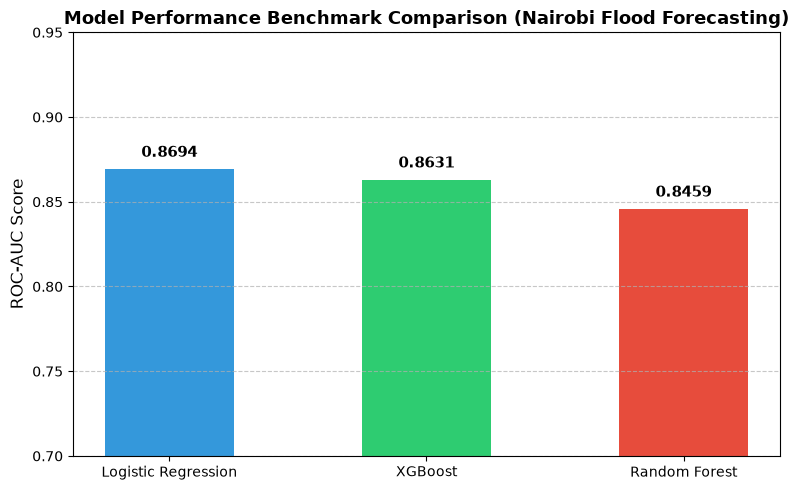

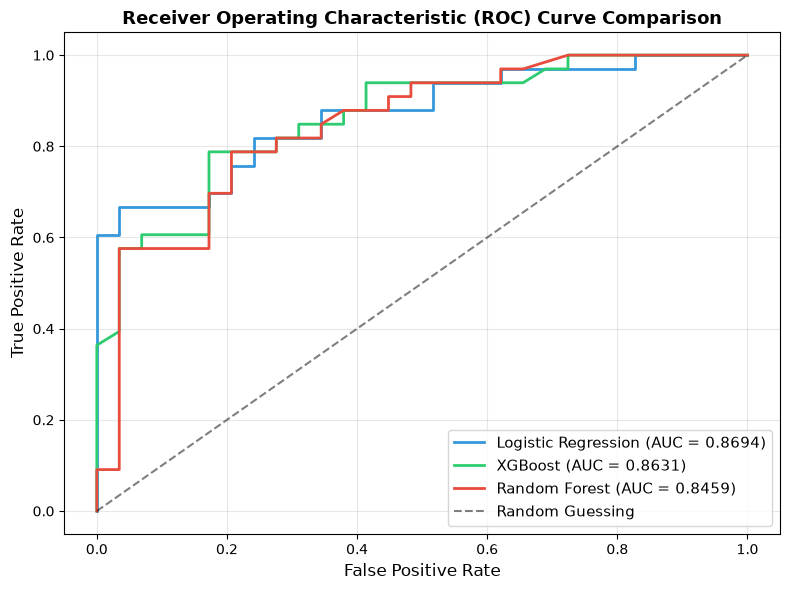

Successfully generated and saved 'model_comparison_bar_chart.png' and 'model_roc_curves.png'!


In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import numpy as np

# 1. Model ROC-AUC Score Comparison Bar Chart
models = ['Logistic Regression', 'XGBoost', 'Random Forest']
auc_scores = [0.8694, 0.8631, 0.8459]
colors = ['#3498db', '#2ecc71', '#e74c3c']

plt.figure(figsize=(8, 5))
bars = plt.bar(models, auc_scores, color=colors, width=0.5)
plt.ylim(0.70, 0.95)
plt.ylabel('ROC-AUC Score', fontsize=12)
plt.title('Model Performance Benchmark Comparison (Nairobi Flood Forecasting)', fontsize=13, fontweight='bold')

# Add score labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.005,
             f'{height:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('model_comparison_bar_chart.png', dpi=300)
plt.show()

# 2. ROC Curves Overlay Plot
plt.figure(figsize=(8, 6))

# Logistic Regression ROC
lr_proba = lr_pipeline.predict_proba(X_test)[:, 1]
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_proba)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = 0.8694)', color='#3498db', linewidth=2)

# XGBoost ROC
xgb_proba = model.predict_proba(X_test)[:, 1]
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_proba)
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = 0.8631)', color='#2ecc71', linewidth=2)

# Random Forest ROC
rf_proba = rf_model.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_proba)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = 0.8459)', color='#e74c3c', linewidth=2)

# Diagonal baseline
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing', alpha=0.5)

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('model_roc_curves.png', dpi=300)
plt.show()

print("Successfully generated and saved 'model_comparison_bar_chart.png' and 'model_roc_curves.png'!")